# Shallow Velocity Model (Model Training)

This notebook is used to estimate the GP hyper-parameters for the shallow velocity model to improve the LA basin in UCVM

### Load Packages

In [1]:
import numpy as np 
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import rcParams as rc
import matplotlib
import os
import math
import matplotlib.colors as mcolors
import torch
import gpytorch
from pyproj import Proj, transform
from mpl_toolkits.mplot3d import Axes3D
from sklearn.preprocessing import StandardScaler
from pickle import dump, load
import linear_operator
import random
from gpytorch.constraints import GreaterThan
import itertools
from collections import defaultdict
from linear_operator import settings as lo_settings
import geopandas as gpd
from shapely.geometry import Polygon


#import user models
from pylib_gp_twoscale import VelGPModel, Genevarikernel

from newloss import LeaveGroupOutPseudoLikelihood


configs = {
    'xtick.direction': 'in',
    'ytick.direction': 'in',
    'font.sans-serif': ['Times New Roman'],
     #'font.sans-serif': ['Microsoft YaHei', 'SimHei', 'Arial', 'Liberation Sans', 'sans-serif'],
    #'font.sans-serif': ['Palatino Linotype', 'Microsoft YaHei', 'SimHei', 'Arial', 'Liberation Sans', 'sans-serif'],
    'axes.grid': True,
    'grid.alpha': 0.5,
    'grid.linestyle': '--',
    'mathtext.fontset': "cm",
    # 'mathtext.rm': "asana math",
    # 'mathtext.cal': "asana math",
    "font.size": 20,
    # 'axes.labelsize': 'large',
    # 'axes.labelpad': 8.0,
    # 'xtick.major.pad': 9.0,
}
rc.update(configs)

In [2]:
cmap = matplotlib.colormaps.get_cmap("coolwarm")
red_color = cmap(0.9)
blue_color = cmap(0.1)
gray_color = cmap(0.5)

color_maps = {
    "input": gray_color,
    "Expected": red_color,
    "Predicted": blue_color,
}

### Define Variables

* define model name

In [3]:
#model column names (input, output)
cn_x = ['vs_depth','Z_2.5','surf_elevation','easting','northing'] #output
cn_y = 'diff'                                                     #input

#data percentiles for test1 and test2
prc_test1 = 0.05
prc_test2 = 0.05

#define random seed
np.random.seed(1)

#define output directories
dir_out = '../Data/Vel_data/'
dir_fig = '../Data/Figure/'
dir_model = './'

# container for hyper parameters
hyper_parameters = {
    'matern_elevation': [],
    'matern_xy': [],
    'outputscale_shape': [],
    'stat_z': [],
    'stat_z2.5': [],
    'stat_elevation': [],
    'stat_scale': [],
    'noise': []}

loss_list = []

### Read Input Files

In [4]:
#read the entire data
df_measure = pd.read_csv(dir_out+'Training_data/df_measure.txt', encoding='utf-8')
df_measure = df_measure.rename(columns={'metadata_id': 'velocity_metadata_id', 'z_2.5': 'Z_2.5',
                                       'vs_middle_depth': 'vs_depth'})
df_measure

,velocity_metadata_id,vs_depth,vs_value,vs_top_depth,vs_bottom_depth,test_id,velocity_name,velocity_method,velocity_date,velocity_quality,...,terrain_class,site_easting,site_northing,test_easting,test_northing,vs_model,surf_elevation,Z_2.5,diff,basin_idnum
0,610,1.00,155.0,0.5,1.5,542,ELC,Suspension Logging,1996-09-26,NaN,...,4,352134.046903,3.786794e+06,352134.046903,3.786794e+06,938.187,251.052,2380.0,-1.800524,2
1,610,2.00,170.2,1.5,2.5,542,ELC,Suspension Logging,1996-09-26,NaN,...,4,352134.046903,3.786794e+06,352134.046903,3.786794e+06,939.068,251.052,2380.0,-1.707914,2
2,610,3.00,196.5,2.5,3.5,542,ELC,Suspension Logging,1996-09-26,NaN,...,4,352134.046903,3.786794e+06,352134.046903,3.786794e+06,939.949,251.052,2380.0,-1.565163,2
3,610,4.00,191.9,3.5,4.5,542,ELC,Suspension Logging,1996-09-26,NaN,...,4,352134.046903,3.786794e+06,352134.046903,3.786794e+06,940.830,251.052,2380.0,-1.589788,2
4,610,5.00,202.0,4.5,5.5,542,ELC,Suspension Logging,1996-09-26,NaN,...,4,352134.046903,3.786794e+06,352134.046903,3.786794e+06,941.711,251.052,2380.0,-1.539431,2
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
11026,2479,12.60,354.0,9.3,15.9,2419,VS,MASW,NaN,NaN,...,8,400420.745906,3.762835e+06,400420.745906,3.762835e+06,894.882,54.938,3620.0,-0.927395,1
11027,2479,21.15,387.0,15.9,26.4,2419,VS,MASW,NaN,NaN,...,8,400420.745906,3.762835e+06,400420.745906,3.762835e+06,899.010,54.938,3620.0,-0.842869,1
11028,2479,34.80,445.0,26.4,43.2,2419,VS,MASW,NaN,NaN,...,8,400420.745906,3.762835e+06,400420.745906,3.762835e+06,905.600,54.938,3620.0,-0.710523,1
11029,2479,56.60,540.0,43.2,70.0,2419,VS,MASW,NaN,NaN,...,8,400420.745906,3.762835e+06,400420.745906,3.762835e+06,916.125,54.938,3620.0,-0.528584,1


In [5]:
groups = [torch.tensor(group.index.to_numpy(), dtype=torch.long)
          for _, group in df_measure.groupby("test_id")]

groups

[tensor([8304, 8305, 8306, 8307, 8308, 8309, 8310, 8311, 8312, 8313, 8314, 8315,
         8316, 8317]),
 tensor([8318, 8319, 8320, 8321, 8322, 8323, 8324]),
 tensor([8325, 8326, 8327, 8328, 8329]),
 tensor([8330, 8331, 8332, 8333, 8334, 8335, 8336]),
 tensor([8337, 8338, 8339, 8340, 8341]),
 tensor([8342, 8343, 8344, 8345, 8346]),
 tensor([8347, 8348, 8349, 8350, 8351, 8352, 8353, 8354]),
 tensor([8355, 8356, 8357, 8358, 8359, 8360, 8361]),
 tensor([8362, 8363, 8364, 8365, 8366, 8367, 8368, 8369, 8370]),
 tensor([8371, 8372, 8373, 8374, 8375, 8376, 8377, 8378, 8379, 8380, 8381]),
 tensor([8382, 8383, 8384, 8385, 8386, 8387, 8388, 8389, 8390]),
 tensor([8391, 8392, 8393, 8394, 8395, 8396, 8397, 8398, 8399]),
 tensor([8400, 8401, 8402]),
 tensor([8403, 8404, 8405]),
 tensor([8406, 8407, 8408, 8409, 8410, 8411, 8412]),
 tensor([8413, 8414, 8415, 8416, 8417]),
 tensor([8418, 8419, 8420]),
 tensor([8421, 8422, 8423]),
 tensor([8424, 8425]),
 tensor([8426, 8427, 8428]),
 tensor([8429, 8430])

In [6]:
df_measure = df_measure[['vs_depth','Z_2.5','surf_elevation','site_easting','site_northing','diff',  'velocity_metadata_id','vs30','basin_idnum']]
df_measure = df_measure.rename(columns={'site_easting': 'easting', 'site_northing': 'northing'})
df_measure

,vs_depth,Z_2.5,surf_elevation,easting,northing,diff,velocity_metadata_id,vs30,basin_idnum
0,1.00,2380.0,251.052,352134.046903,3.786794e+06,-1.800524,610,295.692,2
1,2.00,2380.0,251.052,352134.046903,3.786794e+06,-1.707914,610,295.692,2
2,3.00,2380.0,251.052,352134.046903,3.786794e+06,-1.565163,610,295.692,2
3,4.00,2380.0,251.052,352134.046903,3.786794e+06,-1.589788,610,295.692,2
4,5.00,2380.0,251.052,352134.046903,3.786794e+06,-1.539431,610,295.692,2
...,...,...,...,...,...,...,...,...,...
11026,12.60,3620.0,54.938,400420.745906,3.762835e+06,-0.927395,2479,304.365,1
11027,21.15,3620.0,54.938,400420.745906,3.762835e+06,-0.842869,2479,304.365,1
11028,34.80,3620.0,54.938,400420.745906,3.762835e+06,-0.710523,2479,304.365,1
11029,56.60,3620.0,54.938,400420.745906,3.762835e+06,-0.528584,2479,304.365,1


In [7]:
df_sonic = pd.read_csv(dir_out+'Training_data/df_sonic.txt', encoding='utf-8')
df_sonic = df_sonic.rename(columns={'X': 'easting', 'Y': 'northing',
                                       'depth': 'vs_depth'})
df_sonic

,DEPTH_m,velocity_mps,easting,northing,source_file,TVDSS,velocity,velocity_metadata_id,longitude,latitude,vs_UCVM,vp_UCVM,surf_elevation,ratio,vs,vs_depth,Z_2.5,diff,basin_idnum
0,43.5280,1713.535764,387402.0000,3753149.500,HVD_CVMH_soccom_1.las,43.528000,1702.435158,-29,-118.218003,33.912748,867.819,1684.427,23.596,0.515201,877.096827,67.124000,4400.0,0.010634,1
1,53.5280,1756.154846,387402.0000,3753149.500,HVD_CVMH_soccom_1.las,53.528000,1723.341882,-29,-118.218003,33.912748,871.262,1692.589,23.596,0.514751,887.092079,77.124000,4400.0,0.018006,1
2,63.5280,1738.138676,387402.0000,3753149.500,HVD_CVMH_soccom_1.las,63.528000,1750.140249,-29,-118.218003,33.912748,874.706,1700.750,23.596,0.514306,900.107703,87.124000,4400.0,0.028627,1
3,73.5280,1699.290684,387402.0000,3753149.500,HVD_CVMH_soccom_1.las,73.528000,1779.210020,-29,-118.218003,33.912748,878.150,1708.912,23.596,0.513865,914.273689,97.124000,4400.0,0.040313,1
4,83.5280,1748.027201,387402.0000,3753149.500,HVD_CVMH_soccom_1.las,83.528000,1806.930958,-29,-118.218003,33.912748,881.593,1717.073,23.596,0.513428,927.728573,107.124000,4400.0,0.051009,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3177,1956.3772,3072.301908,387298.0938,3767711.984,tuo_2,1873.377197,3072.714253,-28,-118.221002,34.044045,2107.562,3453.733,83.353,0.610227,1875.053977,1956.730197,2500.0,-0.116894,1
3178,1966.3772,3274.496954,387298.0938,3767711.984,tuo_2,1883.377197,3273.990138,-28,-118.221002,34.044045,2115.348,3464.896,83.353,0.610508,1998.798374,1966.730197,2500.0,-0.056673,1
3179,1976.3772,3338.298432,387298.0938,3767711.984,tuo_2,1893.377197,3338.257238,-28,-118.221002,34.044045,2123.133,3476.058,83.353,0.610788,2038.966008,1976.730197,2500.0,-0.040450,1
3180,1986.3772,3316.756804,387298.0938,3767711.984,tuo_2,1903.377197,3316.470704,-28,-118.221002,34.044045,2130.919,3487.221,83.353,0.611065,2026.579456,1986.730197,2500.0,-0.050204,1


In [8]:
df_sonic = df_sonic[['vs_depth','Z_2.5','surf_elevation','easting','northing','diff',  'velocity_metadata_id']]
df_sonic

,vs_depth,Z_2.5,surf_elevation,easting,northing,diff,velocity_metadata_id
0,67.124000,4400.0,23.596,387402.0000,3753149.500,0.010634,-29
1,77.124000,4400.0,23.596,387402.0000,3753149.500,0.018006,-29
2,87.124000,4400.0,23.596,387402.0000,3753149.500,0.028627,-29
3,97.124000,4400.0,23.596,387402.0000,3753149.500,0.040313,-29
4,107.124000,4400.0,23.596,387402.0000,3753149.500,0.051009,-29
...,...,...,...,...,...,...,...
3177,1956.730197,2500.0,83.353,387298.0938,3767711.984,-0.116894,-28
3178,1966.730197,2500.0,83.353,387298.0938,3767711.984,-0.056673,-28
3179,1976.730197,2500.0,83.353,387298.0938,3767711.984,-0.040450,-28
3180,1986.730197,2500.0,83.353,387298.0938,3767711.984,-0.050204,-28


In [9]:
df_veldata = pd.concat([df_measure.reset_index(drop=True), df_sonic.reset_index(drop=True)], ignore_index=True, sort=False)
df_veldata

,vs_depth,Z_2.5,surf_elevation,easting,northing,diff,velocity_metadata_id,vs30,basin_idnum
0,1.000000,2380.0,251.052,352134.046903,3.786794e+06,-1.800524,610,295.692,2.0
1,2.000000,2380.0,251.052,352134.046903,3.786794e+06,-1.707914,610,295.692,2.0
2,3.000000,2380.0,251.052,352134.046903,3.786794e+06,-1.565163,610,295.692,2.0
3,4.000000,2380.0,251.052,352134.046903,3.786794e+06,-1.589788,610,295.692,2.0
4,5.000000,2380.0,251.052,352134.046903,3.786794e+06,-1.539431,610,295.692,2.0
...,...,...,...,...,...,...,...,...,...
14208,1956.730197,2500.0,83.353,387298.093800,3.767712e+06,-0.116894,-28,NaN,NaN
14209,1966.730197,2500.0,83.353,387298.093800,3.767712e+06,-0.056673,-28,NaN,NaN
14210,1976.730197,2500.0,83.353,387298.093800,3.767712e+06,-0.040450,-28,NaN,NaN
14211,1986.730197,2500.0,83.353,387298.093800,3.767712e+06,-0.050204,-28,NaN,NaN


In [10]:
# get seperate files
_, vp_idx = np.unique(df_veldata.velocity_metadata_id, return_index=True)

df_velprof = df_veldata.loc[vp_idx,['velocity_metadata_id','vs_depth',
                                    'easting','northing',
                                    'Z_2.5','surf_elevation']].reset_index(drop=True)
df_velprof

,velocity_metadata_id,vs_depth,easting,northing,Z_2.5,surf_elevation
0,-33,311.393996,382795.562000,3.761978e+06,5560.0,50.832
1,-32,90.718797,382795.562000,3.761978e+06,5560.0,50.832
2,-31,377.859422,391833.750000,3.760684e+06,5200.0,41.571
3,-30,91.229801,397158.781000,3.757608e+06,4180.0,42.063
4,-29,67.124000,387402.000000,3.753150e+06,4400.0,23.596
...,...,...,...,...,...,...
656,2475,0.750000,494570.169822,3.762546e+06,2500.0,733.439
657,2476,0.450000,420063.686658,3.764811e+06,1840.0,182.872
658,2477,0.500000,431943.461780,3.775829e+06,940.0,392.528
659,2478,0.450000,431258.939147,3.773018e+06,800.0,332.537


findfont: Generic family 'sans-serif' not found because none of the following families were found: Times New Roman
findfont: Generic family 'sans-serif' not found because none of the following families were found: Times New Roman
findfont: Generic family 'sans-serif' not found because none of the following families were found: Times New Roman
findfont: Generic family 'sans-serif' not found because none of the following families were found: Times New Roman
findfont: Generic family 'sans-serif' not found because none of the following families were found: Times New Roman
findfont: Generic family 'sans-serif' not found because none of the following families were found: Times New Roman
findfont: Generic family 'sans-serif' not found because none of the following families were found: Times New Roman
findfont: Generic family 'sans-serif' not found because none of the following families were found: Times New Roman
findfont: Generic family 'sans-serif' not found because none of the following fa

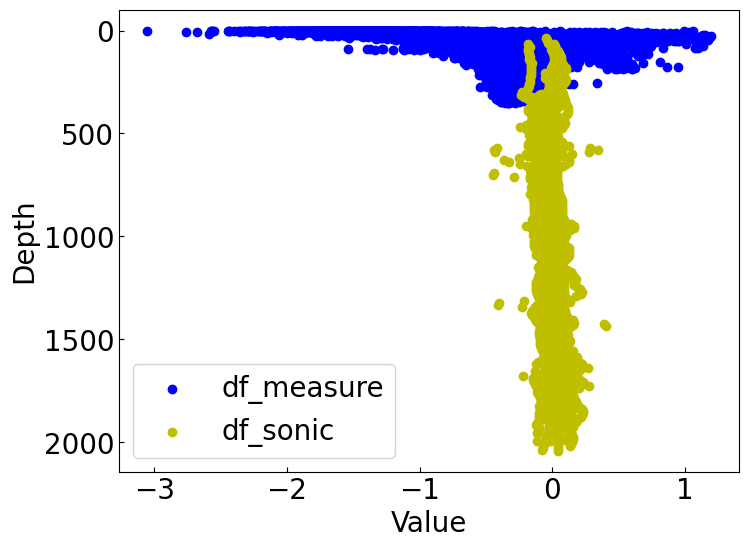

In [11]:
plt.figure(figsize=(8, 6))
plt.scatter(df_measure['diff'], df_measure['vs_depth'], color='b', label="df_measure")
plt.scatter(df_sonic['diff'], df_sonic['vs_depth'], color='y', label="df_sonic")
plt.gca().invert_yaxis()
plt.xlabel("Value")
plt.ylabel("Depth")
plt.legend()
plt.grid()
plt.show()

findfont: Generic family 'sans-serif' not found because none of the following families were found: Times New Roman
findfont: Generic family 'sans-serif' not found because none of the following families were found: Times New Roman
findfont: Generic family 'sans-serif' not found because none of the following families were found: Times New Roman
findfont: Generic family 'sans-serif' not found because none of the following families were found: Times New Roman
findfont: Generic family 'sans-serif' not found because none of the following families were found: Times New Roman
findfont: Generic family 'sans-serif' not found because none of the following families were found: Times New Roman
findfont: Generic family 'sans-serif' not found because none of the following families were found: Times New Roman
findfont: Generic family 'sans-serif' not found because none of the following families were found: Times New Roman
findfont: Generic family 'sans-serif' not found because none of the following fa

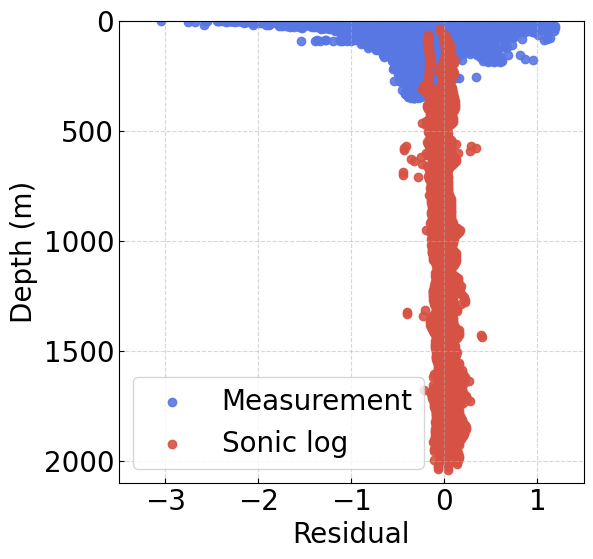

In [12]:
fig, ax = plt.subplots(1, 1, figsize=(6, 6))
ax.scatter(df_measure['diff'], df_measure['vs_depth'],  color=blue_color, label="Measurement",alpha=0.9)
ax.scatter(df_sonic['diff'], df_sonic['vs_depth'],  color=red_color,label="Sonic log",alpha=0.9)

ax.set( xlim=(-3.5, 1.5), ylim=(0, 2100),
       xlabel="Residual",
       ylabel="Depth (m)")
ax.invert_yaxis()
xlim = ax.get_xlim()
ylim = ax.get_ylim()

ax.legend()
#fig.savefig(dir_fig+'vs_data_combine.png', format='png', dpi=300)

### Data Normalization

In [13]:
#initialize standardization
scaler_input  = StandardScaler()

#fit standardization
scaler_input.fit(df_measure.loc[:,cn_x].values)

#assume same scale for easting & northing
scaler_input.scale_[3:] = np.mean(scaler_input.scale_[3:])

device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")

X_train = scaler_input.transform(df_measure.loc[:,cn_x].values)

#get output
Y_train = df_measure.loc[:,cn_y].values



In [14]:
#change into tensor type
dtype = torch.float32


X_train = torch.tensor(X_train, dtype=torch.float32).to(device)
Y_train = torch.tensor(Y_train, dtype=torch.float32).to(device)
#Y_train.var().detach().cpu().numpy()

basin_col = torch.tensor(
    df_measure['basin_idnum'].to_numpy(),
    dtype=X_train.dtype,
    device=X_train.device
).unsqueeze(1)

X_train = torch.cat([X_train, basin_col], dim=1)
X_train

tensor([[-0.8257, -0.1854,  0.2379, -1.0547,  0.5051,  2.0000],
        [-0.8097, -0.1854,  0.2379, -1.0547,  0.5051,  2.0000],
        [-0.7936, -0.1854,  0.2379, -1.0547,  0.5051,  2.0000],
        ...,
        [-0.2832,  0.6963, -0.7933,  0.6197, -0.3257,  1.0000],
        [ 0.0668,  0.6963, -0.7933,  0.6197, -0.3257,  1.0000],
        [ 0.3621,  0.6963, -0.7933,  0.6197, -0.3257,  1.0000]],
       device='cuda:0')

### Construct GP Model

Notes:
* Add constant kernel
* Add separate scales for the kernel
* Add forward model for each kernel seperately

In [15]:
#device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
#device = torch.device('cuda:0')

#define likelihood and model
likelihood = gpytorch.likelihoods.GaussianLikelihood().to(device).double()
model = VelGPModel(X_train, Y_train, likelihood).to(device).double()

In [16]:
rbf_z_param = model.covar_module.rbf_z.raw_lengthscale
base_params = [p for p in model.parameters() if id(p) != id(rbf_z_param)]

optimizer = torch.optim.Adam([
    {'params': base_params, 'lr': 0.01/2},
    {'params': [rbf_z_param], 'lr': 0.02/2},
])

### GP Model Training

In [17]:
hyper_parameters = {
    'matern_elevation': [],
    'matern_xy': [],
    'outputscale_shape': [],
    'stat_z': [],
    'stat_z2.5': [],
    'stat_elevation': [],
    'stat_scale_id': [],
    'stat_scale': [],
    'noise': []}

In [18]:


# ---------------------------
# 0) Build model & likelihood
# ---------------------------
dtype = torch.float32
likelihood = gpytorch.likelihoods.GaussianLikelihood().to(device).double()
model = VelGPModel(X_train, Y_train, likelihood).to(device).double()  # or StaGPModel for your k2-only model

model = model.to(device=device, dtype=dtype)
likelihood = likelihood.to(device=device, dtype=dtype)

# ----------------------------------------
# 1) Load checkpoint (model + likelihood ok)
# ----------------------------------------
ckpt_path = "ucvm_la_basin_adj_model_sta.pth"
if os.path.exists(ckpt_path):
    ckpt = torch.load(ckpt_path, map_location=device)
    # supports either pure state_dict or packaged dict
    if isinstance(ckpt, dict) and ("model_state_dict" in ckpt or "model" in ckpt):
        model.load_state_dict(ckpt.get("model_state_dict", ckpt), strict=False)
        if "likelihood_state_dict" in ckpt:
            likelihood.load_state_dict(ckpt["likelihood_state_dict"], strict=False)
    else:
        # may contain 'likelihood.*' keys; ignore them
        clean_sd = {}
        valid_keys = set(model.state_dict().keys())
        for k, v in ckpt.items():
            if k.startswith("likelihood."): 
                continue
            clean_sd[k] = v if k in valid_keys else v
        model.load_state_dict(clean_sd, strict=False)
    print(f">> loaded checkpoint from {ckpt_path} (strict=False)")

# ---------------------------------------------------
# 2) RELEASE noise constraint (remove hard lower bound)
# ---------------------------------------------------
# If you previously registered a strong floor (e.g., GreaterThan(0.05/0.1)),
# overwrite it with a very small positive lower bound so noise can decrease or increase.
likelihood.noise_covar.register_constraint(
    "raw_noise", gpytorch.constraints.GreaterThan(1e-8)
)
# (Optional) give a sensible initialization so it can move from there
with torch.no_grad():
    # keep current value if you like; or re-init to a mild value
    cur_noise = float(likelihood.noise.detach().cpu())
    if not np.isfinite(cur_noise) or cur_noise <= 0:
        likelihood.noise_covar.initialize(noise=0.05)


likelihood.noise_covar.register_constraint(
    "raw_noise", gpytorch.constraints.GreaterThan(5e-3)  # 或 1e-2
)

base = model.covar_module.shape_kernel.base_kernel
base.register_constraint("raw_lengthscale", gpytorch.constraints.GreaterThan(0.05))





# ---------------------------------------------------
# 3) Freeze k2, train ONLY k1 (shape) + noise
# ---------------------------------------------------
def freeze_k2_train_k1(model, likelihood, train_noise=True):
    for _, p in model.named_parameters():      p.requires_grad = False
    for _, p in likelihood.named_parameters(): p.requires_grad = False

    # enable shape kernel (k1) params
    for name, p in model.named_parameters():
        if name.startswith("covar_module.shape_kernel"):
            p.requires_grad = True

    if train_noise:
        # enable only raw_noise
        likelihood.noise_covar.raw_noise.requires_grad_(True)

freeze_k2_train_k1(model, likelihood, train_noise=True)

# ---------------------------------------------------
# 4) Optimizer: separate LR for k1 vs noise (noise can be larger)
# ---------------------------------------------------
def build_optimizer(model, likelihood, lr_k1=0.05, lr_noise=0.2, weight_decay=0.0):
    params_k1, params_noise = [], []
    for n, p in model.named_parameters():
        if p.requires_grad and n.startswith("covar_module.shape_kernel"):
            params_k1.append(p)
    params_noise.append(likelihood.noise_covar.raw_noise)  # only noise
    return torch.optim.Adam(
        [{"params": params_k1,   "lr": lr_k1,   "weight_decay": weight_decay},
         {"params": params_noise,"lr": lr_noise,"weight_decay": 0.0}]
    )

optimizer = build_optimizer(model, likelihood, lr_k1=0.05, lr_noise=0.2)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, mode='min', factor=0.5, patience=100, verbose=True)

#mll = gpytorch.mlls.ExactMarginalLogLikelihood(likelihood, model)
#mll = gpytorch.mlls.LeaveOneOutPseudoLikelihood(likelihood, model)
mll = LeaveGroupOutPseudoLikelihood(likelihood, model, groups)
# ---------------------------------------------------
# 5) Sanity probe: gradient & update check for noise
# ---------------------------------------------------
model.train(); likelihood.train()
optimizer.zero_grad()
with lo_settings.max_cg_iterations(2000), lo_settings.cg_tolerance(1e-3):
    out = model(X_train)
loss = -mll(out, Y_train)
loss.backward()
print("noise grad max abs =",
      float(likelihood.noise_covar.raw_noise.grad.detach().abs().max().cpu()))
before = float(likelihood.noise.detach().cpu())
optimizer.step()
after  = float(likelihood.noise.detach().cpu())
print(f"noise before -> after: {before:.6g} -> {after:.6g}")

# ----------------------------
# 6) Training loop + recording
# ----------------------------
iter_num = 1500
loss_list = []
hyper_parameters = {
    'matern_elevation': [],
    'matern_xy': [],
    'outputscale_shape': [],
    'stat_z': [],
    'stat_z2.5': [],
    'stat_elevation': [],
    'stat_scale_id': [],
    'stat_scale': [],
    'noise': []}

def snapshot_hparams(model, likelihood):
    K = model.covar_module
    rec = {}

    if hasattr(K, "shape_kernel"):
        shape = K.shape_kernel
        rec["outputscale_shape"] = float(shape.outputscale.detach().cpu().item())

        base = shape.base_kernel
        ell   = float(base.lengthscale.detach().cpu().squeeze()) if hasattr(base, "lengthscale") else float("nan")
        alpha = float(base.alpha.detach().cpu().squeeze())       if hasattr(base, "alpha") else float("nan")

        rec["matern_xy"] = ell
        rec["matern_elevation"] = ell * alpha if (np.isfinite(ell) and np.isfinite(alpha)) else float("nan")
    else:
        rec["outputscale_shape"] = float("nan")
        rec["matern_xy"] = float("nan")
        rec["matern_elevation"] = float("nan")

    rec["stat_z"] = float(K.rbf_z.lengthscale.detach().cpu().squeeze()) \
        if hasattr(K, "rbf_z") else float("nan")

    # params lengthscale (Z2.5, elevation/surf_elevation)
    if hasattr(K, "rbf_params"):
        ls = K.rbf_params.lengthscale.detach().cpu().squeeze()
        ls = np.asarray(ls)
        rec["stat_z2.5"] = float(ls[0]) if ls.size >= 1 else float("nan")
        rec["stat_elevation"] = float(ls[1]) if ls.size >= 2 else float("nan")
    else:
        rec["stat_z2.5"] = float("nan")
        rec["stat_elevation"] = float("nan")

    # outputscale of params
    rec["stat_scale"] = float(K.rbf_params_scl.outputscale.detach().cpu().item()) \
        if hasattr(K, "rbf_params_scl") else float("nan")

    # constant kernel
    rec["stat_scale_id"] = float(K.kid_scl.outputscale.detach().cpu().item()) \
        if hasattr(K, "kid_scl") else float("nan")


    # noise
    rec["noise"] = float(likelihood.noise.detach().cpu().item())

    return rec


model.train(); likelihood.train()
for i in range(iter_num):
    optimizer.zero_grad()
    with lo_settings.max_cg_iterations(2000), lo_settings.cg_tolerance(1e-3):
        output = model(X_train)
    loss = -mll(output, Y_train)
    loss.backward()
    optimizer.step()
    scheduler.step(loss.item())

    loss_list.append(float(loss.item()))
    hp = snapshot_hparams(model, likelihood)
    for k in hyper_parameters.keys():
        hyper_parameters[k].append(hp.get(k, float("nan")))

    print(f"[shape+noise] iter {i+1:4d} | loss {loss.item():.6f} | noise {hp['noise']:.6g}")

# save history
N = len(loss_list)
df_hist = pd.DataFrame(hyper_parameters)
df_hist.insert(0, "iteration", range(1, N+1))
df_hist["loss"] = loss_list
#df_hist.to_csv("gp_shape_only_history_released_noise.csv", index=False)
df_hist

>> loaded checkpoint from ucvm_la_basin_adj_model_sta.pth (strict=False)


/home/yiliu2/miniconda3/envs/python3.11/lib/python3.11/site-packages/torch/optim/lr_scheduler.py:62: UserWarning: The verbose parameter is deprecated. Please use get_last_lr() to access the learning rate.
  warnings.warn(


noise grad max abs = 0.3245090842247009
noise before -> after: 0.698147 -> 0.603139
[shape+noise] iter    1 | loss 0.744945 | noise 0.517958
[shape+noise] iter    2 | loss 0.675284 | noise 0.442313
[shape+noise] iter    3 | loss 0.604016 | noise 0.375764
[shape+noise] iter    4 | loss 0.531559 | noise 0.317744
[shape+noise] iter    5 | loss 0.458407 | noise 0.267594
[shape+noise] iter    6 | loss 0.385125 | noise 0.224598
[shape+noise] iter    7 | loss 0.312358 | noise 0.188013
[shape+noise] iter    8 | loss 0.240826 | noise 0.157098
[shape+noise] iter    9 | loss 0.171323 | noise 0.131143
[shape+noise] iter   10 | loss 0.104722 | noise 0.109479
[shape+noise] iter   11 | loss 0.041958 | noise 0.0914968
[shape+noise] iter   12 | loss -0.015980 | noise 0.0766469
[shape+noise] iter   13 | loss -0.068084 | noise 0.0644447
[shape+noise] iter   14 | loss -0.113382 | noise 0.0544682
[shape+noise] iter   15 | loss -0.151011 | noise 0.0463536
[shape+noise] iter   16 | loss -0.180325 | noise 0.0

,iteration,matern_elevation,matern_xy,outputscale_shape,stat_z,stat_z2.5,stat_elevation,stat_scale_id,stat_scale,noise,loss
0,1,0.227451,0.794356,0.644436,0.437842,0.009327,0.044404,0.120371,0.048511,0.517958,0.744945
1,2,0.245410,0.820800,0.621101,0.437842,0.009327,0.044404,0.120371,0.048511,0.442313,0.675284
2,3,0.264575,0.847749,0.598476,0.437842,0.009327,0.044404,0.120371,0.048511,0.375764,0.604016
3,4,0.284979,0.875150,0.576586,0.437842,0.009327,0.044404,0.120371,0.048511,0.317744,0.531559
4,5,0.306648,0.902940,0.555454,0.437842,0.009327,0.044404,0.120371,0.048511,0.267594,0.458407
...,...,...,...,...,...,...,...,...,...,...,...
1495,1496,0.086642,0.050223,0.026150,0.437842,0.009327,0.044404,0.120371,0.048511,0.022679,-0.266914
1496,1497,0.086641,0.050223,0.026150,0.437842,0.009327,0.044404,0.120371,0.048511,0.022679,-0.266912
1497,1498,0.086641,0.050222,0.026150,0.437842,0.009327,0.044404,0.120371,0.048511,0.022679,-0.266918
1498,1499,0.086640,0.050222,0.026151,0.437842,0.009327,0.044404,0.120371,0.048511,0.022679,-0.266916


/tmp/ipykernel_699340/245469834.py:10: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend()


findfont: Generic family 'sans-serif' not found because none of the following families were found: Times New Roman
findfont: Generic family 'sans-serif' not found because none of the following families were found: Times New Roman
findfont: Generic family 'sans-serif' not found because none of the following families were found: Times New Roman
findfont: Generic family 'sans-serif' not found because none of the following families were found: Times New Roman
findfont: Generic family 'sans-serif' not found because none of the following families were found: Times New Roman
findfont: Generic family 'sans-serif' not found because none of the following families were found: Times New Roman
findfont: Generic family 'sans-serif' not found because none of the following families were found: Times New Roman
findfont: Generic family 'sans-serif' not found because none of the following families were found: Times New Roman
findfont: Generic family 'sans-serif' not found because none of the following fa

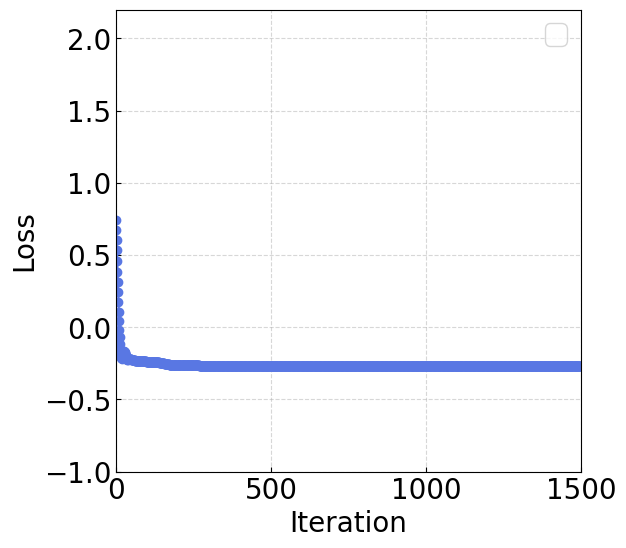

In [19]:
fig, ax = plt.subplots(1, 1, figsize=(6, 6))
ax.plot(range(0, iter_num), loss_list,  color=blue_color, marker='o')

ax.set( xlim=(-0.5, iter_num), ylim=(-1, 2.2),
       xlabel="Iteration",
       ylabel="Loss")
xlim = ax.get_xlim()
ylim = ax.get_ylim()

ax.legend()

findfont: Generic family 'sans-serif' not found because none of the following families were found: Times New Roman
findfont: Generic family 'sans-serif' not found because none of the following families were found: Times New Roman
findfont: Generic family 'sans-serif' not found because none of the following families were found: Times New Roman
findfont: Generic family 'sans-serif' not found because none of the following families were found: Times New Roman
findfont: Generic family 'sans-serif' not found because none of the following families were found: Times New Roman
findfont: Generic family 'sans-serif' not found because none of the following families were found: Times New Roman
findfont: Generic family 'sans-serif' not found because none of the following families were found: Times New Roman
findfont: Generic family 'sans-serif' not found because none of the following families were found: Times New Roman
findfont: Generic family 'sans-serif' not found because none of the following fa

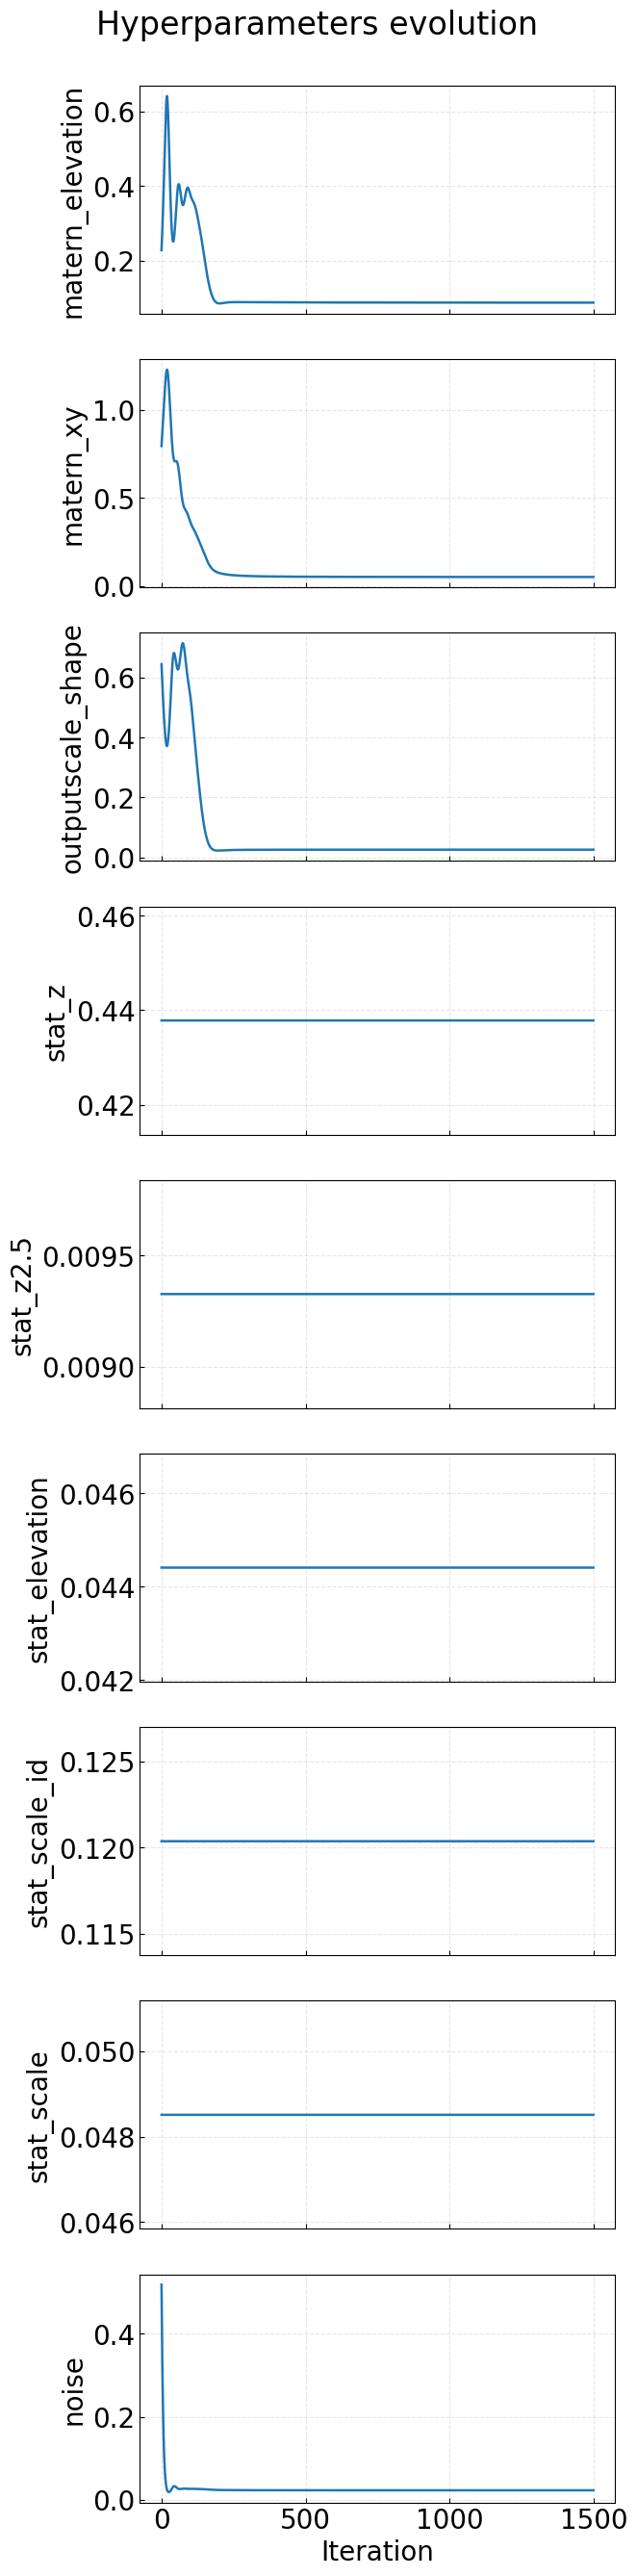

In [20]:
names = list(hyper_parameters.keys())
K = len(names)
fig, axes = plt.subplots(K, 1, figsize=(7, 3*K), sharex=True)

if K == 1: axes = [axes]
for ax, name in zip(axes, names):
    vals = np.asarray(hyper_parameters[name]).ravel()
    ax.plot(vals, linewidth=1.8)
    ax.set_ylabel(name)
    ax.grid(True, alpha=0.3)
axes[-1].set_xlabel("Iteration")
fig.suptitle("Hyperparameters evolution", y=0.995)
fig.tight_layout()
# fig.savefig("hyperparameters_evolution_grid.png", dpi=300)
plt.show()

### Save Transformations and GP

In [21]:
#save input transformation
dump(scaler_input, open(dir_model+'ucvm_la_basin_adj_scaler_frozen.pkl', 'wb'))

#save gp model
torch.save(model.state_dict(), dir_model+'ucvm_la_basin_adj_model_frozen_newloss.pth')

### Output hyperparameters

In [22]:
df_hist.to_csv(dir_out+'Hyperparameters/vs_data_hyper_step2.txt', index=False,
                  encoding='utf-8',
                  lineterminator='\n')